<a href="https://colab.research.google.com/github/anaishinschberger-cloud/TEST_Gaussian_Splatting/blob/main/notebooks/render.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")

# Récupérer les données COLMAP
source = "/content/drive/MyDrive/data/images_tasse/colmap_light"
shutil.copytree(source + "/images", "/content/tasse_light/images", dirs_exist_ok=True)
shutil.copytree(source + "/sparse", "/content/tasse_light/sparse", dirs_exist_ok=True)

# Récupérer le code officiel
%cd /content
!git clone https://github.com/graphdeco-inria/gaussian-splatting --recursive

%cd /content/gaussian-splatting

# Installer les dépendances
!pip install -q plyfile tqdm opencv-python joblib
os.environ["NVCC_PREPEND_FLAGS"] = "--pre-include cstdint"
!pip install -q --no-build-isolation ./submodules/diff-gaussian-rasterization ./submodules/simple-knn

Mounted at /content/drive
/content
Cloning into 'gaussian-splatting'...
remote: Enumerating objects: 1053, done.
remote: Total 1053 (delta 0), reused 0 (delta 0), pack-reused 1053 (from 1)
Receiving objects: 100% (1053/1053), 78.72 MiB | 19.12 MiB/s, done.
Resolving deltas: 100% (593/593), done.
Submodule 'SIBR_viewers' (https://gitlab.inria.fr/sibr/sibr_core.git) registered for path 'SIBR_viewers'
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/graphdeco-inria/diff-gaussian-rasterization.git) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/fused-ssim' (https://github.com/rahul-goel/fused-ssim.git) registered for path 'submodules/fused-ssim'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/content/gaussian-splatting/SIBR_viewers'...
remote: Enumerating objects: 3293, done.        
remote: Counting objects: 100% (322/322), done.        
re

In [2]:
!python render.py \
    -m /content/drive/MyDrive/data/images_tasse/gaussian_model_3000 \
    -s /content/tasse_light \
    --iteration 3000 \
    --skip_test

Looking for config file in /content/drive/MyDrive/data/images_tasse/gaussian_model_3000/cfg_args
Config file found: /content/drive/MyDrive/data/images_tasse/gaussian_model_3000/cfg_args
Rendering /content/drive/MyDrive/data/images_tasse/gaussian_model_3000
Loading trained model at iteration 3000 [14/11 15:00:40]
Reading camera 67/67 [14/11 15:00:41]
Converting point3d.bin to .ply, will happen only the first time you open the scene. [14/11 15:00:41]
Loading Training Cameras [14/11 15:00:41]
Loading Test Cameras [14/11 15:00:45]
Rendering progress: 100% 67/67 [01:11<00:00,  1.07s/it]


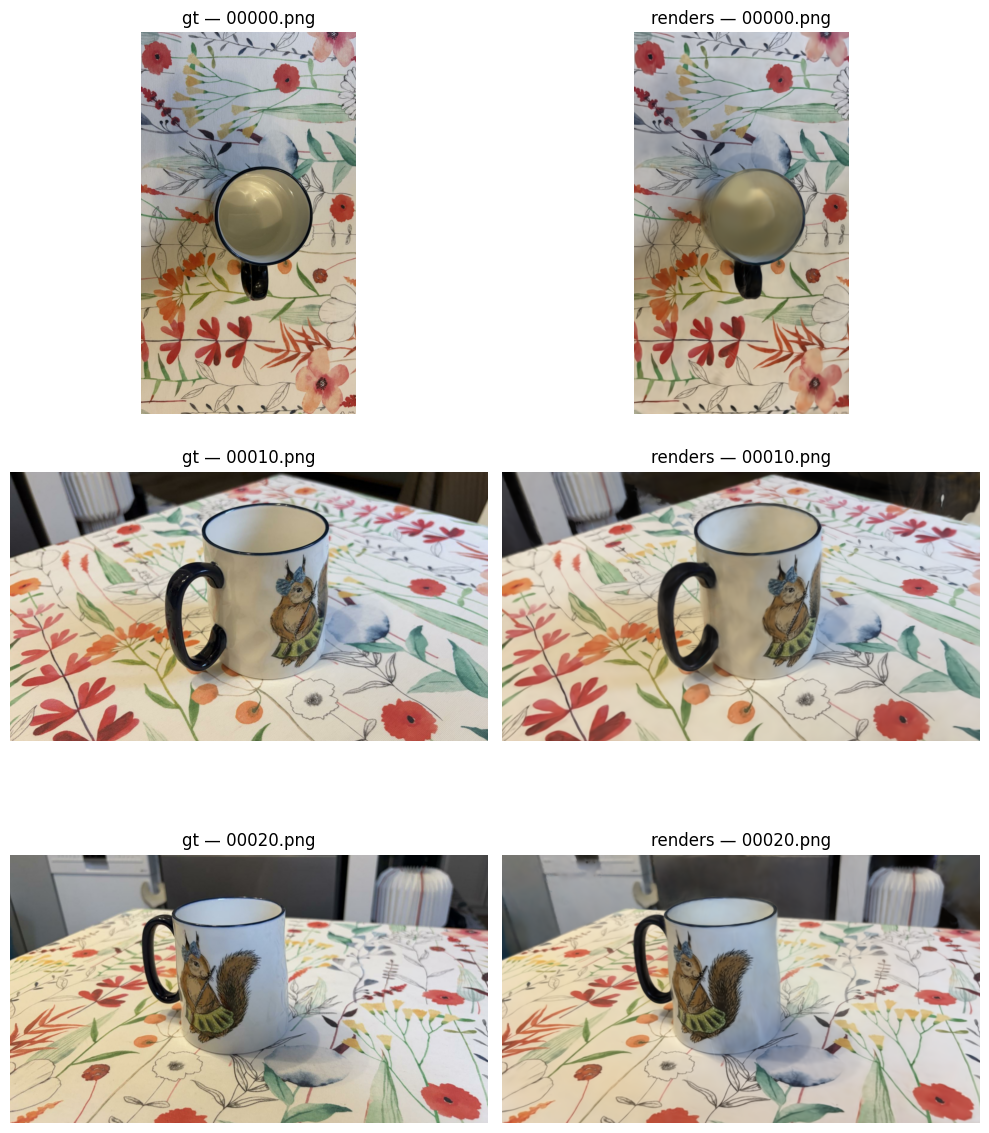

In [3]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

d = Path("/content/drive/MyDrive/data/images_tasse/gaussian_model_3000/train/ours_3000")
images = sorted((d / "renders").glob("*.png"))

indices = [0, 10, 20]  # Images à comparer

fig, axes = plt.subplots(len(indices), 2, figsize=(10, 4 * len(indices)))

for j, i in enumerate(indices):
    nom = images[i].name

    for k, dossier in enumerate(["gt", "renders"]):
        axes[j, k].imshow(Image.open(d / dossier / nom))
        axes[j, k].set_title(f"{dossier} — {nom}")
        axes[j, k].axis("off")

plt.tight_layout()
plt.show()